# Лабораторная работа № 2. Microwave circuits wave propagation

**Интервенции, распределения параметров и выбор ветвей графа Максвелла.**

Основа — [первая лабораторная gkarpeev/maxwell](https://github.com/gkarpeev/maxwell/tree/b88901cc688be82a7de1716ef428026a33e4c7db).
Чужая работа сохранена отдельно и атрибутирована. Повторно используются типизированный DAG,
уравнения Максвелла, аналитические волны, FDTD-проверка и универсальный подбор одного параметра.
Этот ноутбук добавляет статистический эксперимент второй лабораторной.

В исходной работе **PDEArena и EMVal — синтетика**, а не измерения. Поэтому требование
о реальных данных выполнено на отдельном эксперименте Hatab et al. (2023), сохраняя
ту же физическую основу — уравнения Максвелла. Данные, методы и все результаты воспроизводятся
при **Restart Kernel → Run All**. Требуется `pip install -r lab02/requirements.txt` из корня репозитория.

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd()
if ROOT.name == 'lab02': ROOT = ROOT.parent
if not (ROOT / 'lab02/model.py').exists(): raise RuntimeError('Запустите ноутбук из корня проекта или lab02')
sys.path.insert(0, str(ROOT))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / 'tmp/lab02/mpl'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from lab02.experiment import run, load
from lab02 import plotting
from lab02.model import propagation_graph
from lab02.upstream import maxwell_model
get_ipython().run_line_magic('matplotlib', 'inline')

## 1. Уравнение и связь с первой лабораторной

В нормировке автора $\mathbf e=\sqrt{\epsilon_0}\mathbf E$,
$\mathbf h=\sqrt{\mu_0}\mathbf H$, при $\mu_r=1$:

$$\partial_t\mathbf e=\frac{c}{\epsilon_r}\nabla\times\mathbf h
-\frac{\sigma}{\epsilon_0\epsilon_r}\mathbf e,
\qquad\partial_t\mathbf h=-c\nabla\times\mathbf e.$$

$\epsilon_r$ задаёт скорость распространения, $\sigma$ — электрические потери.
В первой лабораторной использован случай $\sigma=0$; вариант с потерями уже предусмотрен
функцией `maxwell_model(lossy=True)` автора. Собственные источники не вносятся в исследуемую
однородную область. Скорость света $c=299792458$ м/с фиксирована.

Для СВЧ-линии берём одну TEM-моду с конвенцией
$$E_y(x,t)=\Re\{E_0e^{-\gamma(f)x}e^{i\omega t}\},\quad
\gamma=\alpha+i\beta,\quad\omega=2\pi f.$$
$\alpha$ — затухание амплитуды в Нп/м; $\beta$ — фазовый набег в рад/м.
Это ограниченный класс решений PDE Максвелла, а не произвольный временной ряд.
Частоты в измерениях **не являются моментами времени**.

В слабозатухающей линии телеграфное представление даёт
$\gamma=\sqrt{(R+i\omega L)(G+i\omega C)}$.
Поверхностный импеданс хорошего проводника имеет вклады $(1+i)\sqrt f$;
потери с почти постоянным $\tan\delta$ дают вклад в затухание, пропорциональный $f$.
Исследуем эффективную трёхпараметрическую модель на конечной полосе:

$$u=f/f_0,\quad f_0=10\,\text{ГГц},\qquad
\alpha=a\sqrt u+b u,\qquad
\beta=\frac{2\pi f}{c}n+a\sqrt u.$$

$n$ безразмерен; $a,b$ имеют единицы Нп/м и численно рад/м для фазовой части.
В отсутствии потерь $n=\sqrt{\epsilon_r}$.
Величина $n^2$ здесь — **высокочастотный эффективный фон**, а не независимо измеренная
объёмная проницаемость материала. Член $b$ описывает дополнительный частотный вклад;
его наличие ещё не доказывает конкретный механизм диэлектрических потерь.

Формула — наша редукция для второй лабораторной, а не модель, дословно взятая у Hatab.
Для каждого тона можно проверить точную совместимость экспоненты с Максвеллом:
$$\epsilon_{r,\mathrm{eff}}(f)=\frac{c^2(\beta^2-\alpha^2)}{\omega^2},\quad
\frac{\sigma_{\mathrm{eff}}(f)}{\epsilon_0}=\frac{2c^2\alpha\beta}{\omega},\quad
\widehat h_z=\frac{c\gamma}{i\omega}\widehat e_y.$$
Это частотная эффективная среда; её нельзя автоматически считать исходной моделью
с постоянными $\epsilon_r,\sigma$ на всех частотах или доказательством глобальной причинности.

## 2. Совместимая тройка методов: обоснование

**Распределение параметров — moving-block pairs bootstrap.** На каждой реплике выбираем
с возвращением блоки соседних частот и заново оцениваем $\theta=(n,a,b)$.
Внутри блока сохраняются порядок частот и пара $(\alpha,\beta)$.
Независимое перемешивание всех скаляров разрушило бы частотную и межканальную зависимость.
Основная длина блока — 8 частотных точек (шаг 100 МГц); проверяем также 4 и 12.
Предполагается, что локальная зависимость остатков достаточно короткая для такой аппроксимации.
Это условная эмпирическая оценка неопределённости, не апостериорное распределение и не
полная метрологическая неопределённость прибора.

**Интервенция — условное зашумление наблюдаемых $\alpha$, $\beta$ или обоих каналов.**
На обучающих частотах строим пилотную модель, локальные масштабы остатков $s_j(f)$,
центрируем $z_{ij}=r_{ij}/s_j(f_i)$. Из их **парных блоков** генерируем шум:
$$y_j^{(\lambda)}(f_i)=y_j(f_i)+\lambda s_j(f_i)z^*_{ij},
\qquad\lambda\in\{0,0.5,1,2,4\}.$$
Масштаб зависит от частоты, а совместные блоки сохраняют часть корреляции каналов.
Проверочные значения не участвуют ни в пилотном подборе, ни в оценке шума.
Это вычислительное вмешательство в обработанные измерения $\gamma$, не физическое
изменение установки и не эксперимент `do` над причинным графом.

На каждой бутстреп-реплике генерируется новая реализация вмешательства: сравниваем смесь
распределений по повторному выбору частотных блоков и по шуму. Для всех $\lambda$ используем
одни и те же индексы и базовый шум, поэтому при $\lambda=0$ распределения совпадают точно.
Не предполагается, что остатки полностью состоят из приборного шума: в них может быть ошибка модели.

**Расстояние — Вассерштейна порядка 1.**
$$W_1(P,Q)=\int |F_P(t)-F_Q(t)|\,dt.$$
Оно определено непосредственно на эмпирических выборках и не требует KDE или
псевдосчётчиков в пустых ячейках, как оценка KL. Для каждого параметра сохраняем
расстояние в исходных единицах и нормируем на **фиксированное** SD исходного бутстрепа.
Дополнительно считаем среднее $W_1$ по 128 фиксированным единичным проекциям
стандартизованного вектора — приближённое sliced-Wasserstein, а не точное многомерное $W_1$.
Это важно из-за компенсации параметров $a,b$, которую не видно по одним маргинальным гистограммам.

Параллельно сравниваем функции ошибки: взвешенную квадратичную и `soft_l1` с масштабом 1.
В обоих случаях масштабы $s_j(f)$ фиксируются до вмешательства. У квадратичной задачи
есть точное решение через линейную алгебру; `soft_l1` решается SciPy TRF.

## 3. Данные, разбиение и проверка старого кода

**Синтетика.** $151$ частота от 3 до 18 ГГц, известные $n=2$, $a=0.06$, $b=0$.
К точному решению добавлен неоднородный по частоте AR(1)-шум с корреляцией $0.6$.
Это контроль, в котором одна ветвь заведомо отсутствует. Независимо воспроизводим
аналитические трёхмерные волны студента, подбор $\epsilon_r=4$ и FDTD на сетках $12^3,24^3$.

**Реальные измерения.** Hatab et al., *Sensors* 23(9), 4548 (2023),
[DOI статьи](https://doi.org/10.3390/s23094548),
[данные и код](https://doi.org/10.3217/6bd26-5cp67).
Измеряли плоскую коаксиальную воздушную линию Maury Microwave 8045P;
по ней перемещали отражающий и пропускающий элемент без переподключения кабелей.
Взяты исходные Touchstone-файлы для 10 положений от 0 до 192 мм и трёх VNA.
Авторский алгоритм `mN_at_one_freq`, без изменений, восстанавливает комплексную
постоянную распространения. **В этом опыте не измерялись объёмные временные поля $E,H$.**

Основной анализ — R&S ZNA: 151 частота, 3–18 ГГц. VectorStar (3–18 ГГц)
и ENA (3–14 ГГц) — дополнительная проверка между приборами; они не используются для подбора.
Они измеряли ту же линию, поэтому это не независимые экземпляры материала.

Каждая четвёртая полоса из 8 соседних частот оставляется для контроля:
119 частот для обучения, 32 для проверки. Блоки бутстрепа не пересекают разрывы между
обучающими полосами. Порог выбора структуры заранее фиксирован в следующем разделе;
проверочная ошибка участвует в выборе структуры, поэтому она **не является** окончательной
ошибкой на полностью независимом тестовом наборе.

In [2]:
# Полный эксперимент: исходные S-параметры заново преобразуются в gamma.
# 1000 реплик для каждого режима; фиксированный seed, CPU, интернет не нужен.
report = run(n_boot=1000, rebuild_data=True)
report, arrays = load()
display(pd.DataFrame(report['upstream_check']['fdtd_convergence']))
print('Подбор epsilon_r старым кодом:', report['upstream_check']['epsilon_fit'])
print('Отношение ошибок FDTD:', report['upstream_check']['electric_error_ratio'])

Dataset: synthetic


  bootstrap linear


  block sensitivity 4


  block sensitivity 12


  bootstrap soft_l1


...

  block sensitivity 4


  block sensitivity 12


  bootstrap soft_l1


,n,dt_s,time_s,electric_relative_l2,magnetic_relative_l2,relative_energy_drift,div_e_dimensionless,div_h_dimensionless
0,12,3.335641e-12,4.002769e-11,0.017898,0.019397,0.000110,2.664535e-14,1.598721e-14
1,24,1.667820e-12,4.002769e-11,0.004574,0.004761,0.000007,8.931522e-14,5.928591e-14


Подбор epsilon_r старым кодом: 4.000000000793404
Отношение ошибок FDTD: 3.9129964567678894


Отношение ошибок при двукратном уточнении близко к четырём, что соответствует второму
порядку схемы Yee. Точный подбор на аналитических полях проверяет переиспользованный
оптимизатор отдельно от FDTD-дискретизации. Основные статистические расчёты используют
гармоническое решение; тысячи FDTD-запусков не подменяются утверждением об их выполнении.

In [3]:
summary=[]
for name,info in report['datasets'].items():
    summary.append(dict(dataset=name,n=info['parameters'][0],a=info['parameters'][1],b=info['parameters'][2],
        epsilon_background=info['epsilon_asymptotic'],
        RMSE_alpha=info['validation_rmse_alpha_beta'][0],RMSE_beta=info['validation_rmse_alpha_beta'][1]))
display(pd.DataFrame(summary))
display(pd.DataFrame(report['cross_instrument']).T)

,dataset,n,a,b,epsilon_background,RMSE_alpha,RMSE_beta
0,synthetic,1.999997,0.061703,-0.001753,3.999988,0.002316,0.005366
1,measured,1.003318,0.060193,0.003571,1.006646,0.003271,0.009448


,n,frequency_GHz,rmse_alpha_beta
ENA,111,"[3.0, 14.0]","[0.00195072456832684, 0.007391940473815961]"
VectorStar,151,"[3.0, 18.0]","[0.0018645429881400846, 0.01287432814204278]"


## 4. Граф и параметры

Используется `ExpressionDAG` студента: направленные рёбра идут от аргумента к операции,
порядок аргументов хранится отдельно. Матрица $Z_{ij}$ — число вхождений вершины $j$
в операцию $i$; она транспонирована относительно обычной матрицы NetworkX.

- $n$: ребро к фазовой операции $k_0 n$. Нулевая гипотеза — **$n=1$**, то есть
  удаление поправки относительно вакуумной скорости, а не бессмысленное $n=0$.
- $a$: узел коэффициента проводникового вклада и **оба** его пути — в $\alpha$ и $\beta$.
  Удалять только один путь было бы физически несогласованно.
- $b$: узел коэффициента, умножение $b(f/f_0)$ и соответствующий вход суммы $\alpha$.
  При $b=0$ эта ветвь удаляется, но потери от $a$ остаются.

В исходном графе Максвелла $n$ связан с делением на эффективную проницаемость,
$a,b$ — с частотно зависимым электрическим демпфированием и дисперсией.
Это уточнение одного коэффициента исходного графа на два механизма в редуцированной модели;
удаление $b$ не означает удаления всей ветви проводимости и тем более уравнения Максвелла.

,0,1,2,3,4,5,6,7,8,9,10
0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,0
6,0,1,0,1,0,0,0,0,0,0,0
7,0,0,1,0,1,0,0,0,0,0,0
8,0,0,0,0,0,0,1,1,0,0,0
9,1,0,0,0,0,1,0,0,0,0,0


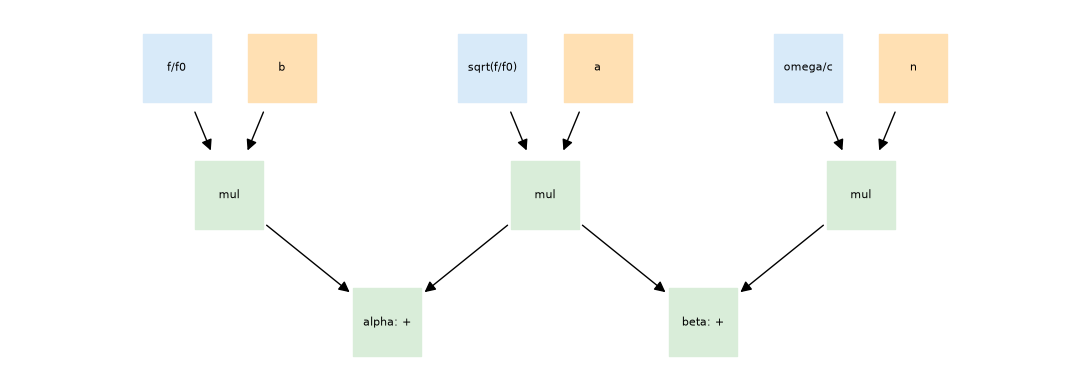

Исходный граф студента: 16 вершин; вариант с потерями: 20


In [4]:
graph = propagation_graph()
display(pd.DataFrame(graph.adjacency()))
fig = plotting.graph_plot(); display(fig); plt.close(fig)
print('Исходный граф студента:', len(maxwell_model().nodes), 'вершин; вариант с потерями:', len(maxwell_model(True).nodes))

Граф выше — наблюдательная редукция гармонического решения с двумя выходами.
В `results/` также сохранены исходные графы студента с потерями и без потерь,
их матрицы, а после отбора — отдельный выбранный граф для каждого набора данных. Также сохранены полные графы Максвелла с подстановкой эффективных материальных коэффициентов (`*maxwell_expanded_graph.json`) и соответствие исходным узлам (`parameter_graph_map.json`). В коде студента `gamma` — это sigma/epsilon0 в 1/с; этот параметр отличается от нашей комплексной постоянной распространения gamma в 1/м.

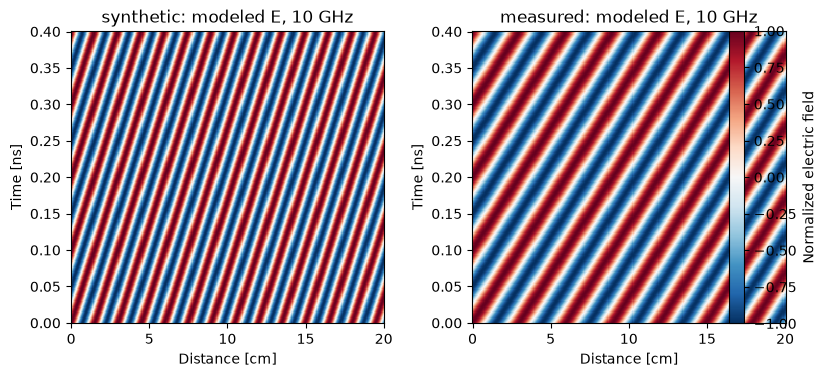

In [5]:
fig = plotting.wave_plot(report); display(fig); plt.close(fig)

Карты показывают **рассчитанное** распространение одной гармоники 10 ГГц:
направление наклона полос связано со скоростью фазы. При $n\approx2$ волна распространяется
примерно вдвое медленнее, чем при $n\approx1$. Даже правая карта построена по модели,
подобранной к измерениям; она не является непосредственно измеренным полем.

## 5.1. Синтетические данные

Маркеры выделяют контрольные частотные полосы. Кривая модели подбиралась только по остальным полосам.

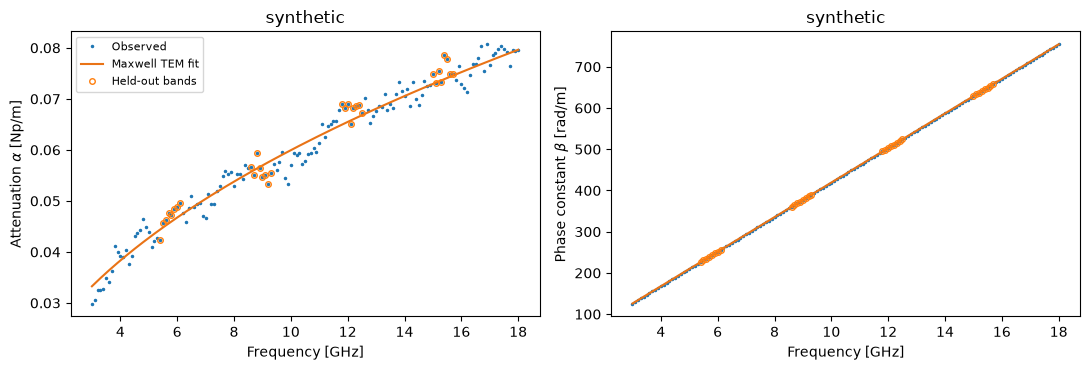

In [6]:
fig = plotting.observations('synthetic', report, arrays); display(fig); plt.close(fig)

Низкая ошибка фазового канала сама по себе не гарантирует точность потерь: масштаб
$\beta$ на несколько порядков больше масштаба $\alpha$. Поэтому оптимизация использует
два отдельно нормированных канала и ниже выводятся обе RMSE.

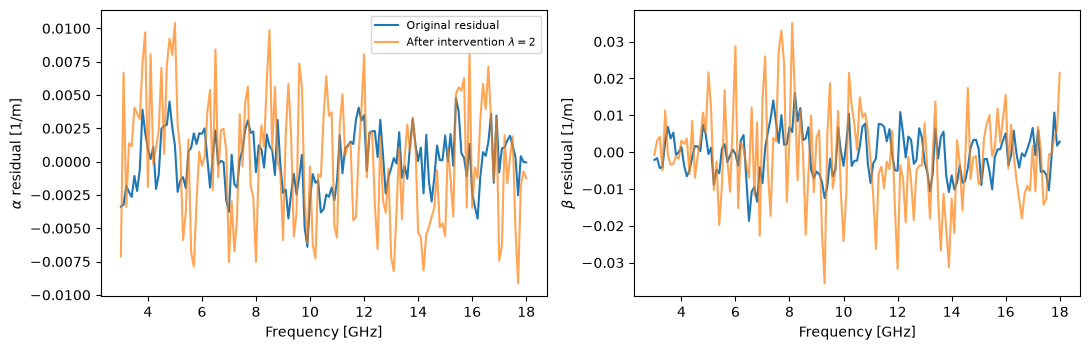

In [7]:
fig = plotting.intervention('synthetic', report, arrays); display(fig); plt.close(fig)

Здесь показан один пример добавления условного блочного шума с $\lambda=2$.
Для распределений ниже используется не одна эта реализация, а новая реализация
вмешательства на каждой реплике. Поэтому рассматриваются и смещение, и рост разброса оценок.

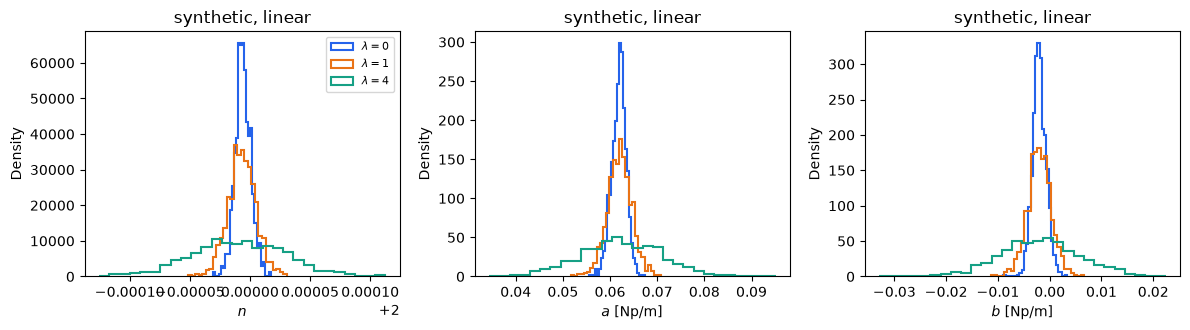

In [8]:
fig = plotting.distributions('synthetic', 'linear', arrays); display(fig); plt.close(fig)

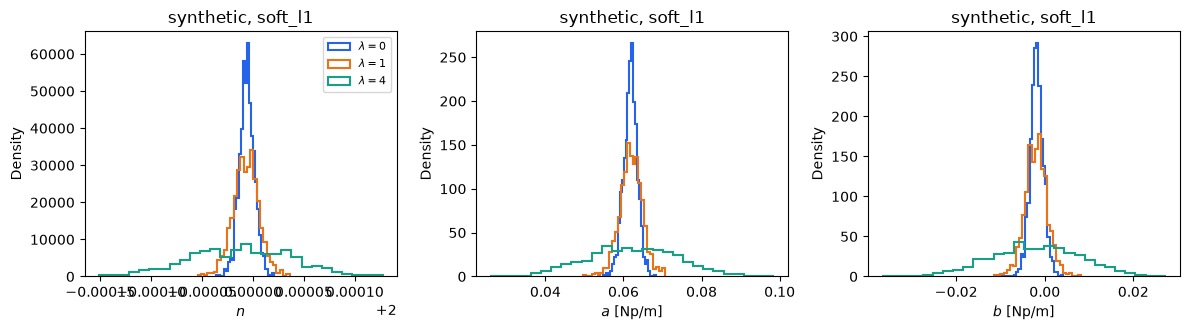

In [9]:
fig = plotting.distributions('synthetic', 'soft_l1', arrays); display(fig); plt.close(fig)

Гистограммы относятся к одной и той же процедуре бутстрепа; сравниваются функции ошибки
`linear` и `soft_l1`. Увеличение ширины распределения не доказывает изменение истинной
проницаемости: в этом опыте изменена наблюдаемая выборка, а не физическая среда.

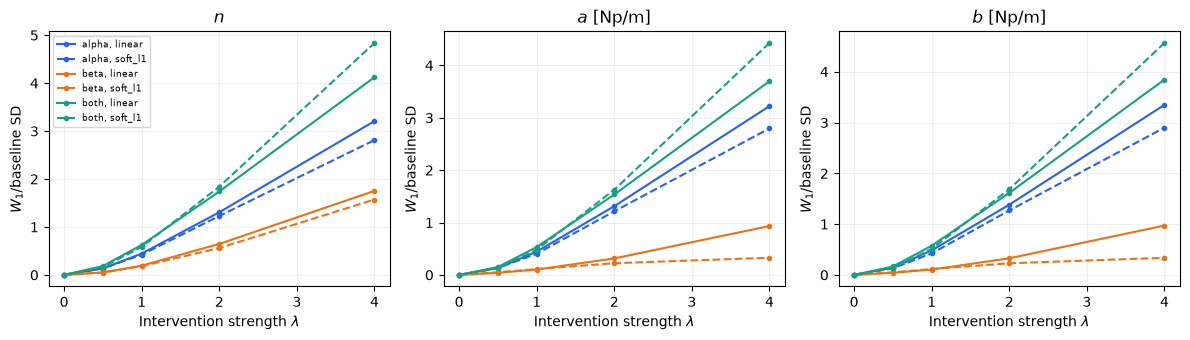

In [10]:
fig = plotting.distance_plot('synthetic', arrays); display(fig); plt.close(fig)

Цвет задаёт зашумлённую переменную, стиль линии — функцию ошибки. Нормировочное SD
не пересчитывается после вмешательства. В нуле все расстояния должны точно равняться нулю;
рост расстояния при увеличении шума отражает чувствительность оценки параметра.
Строгая монотонность одной конечной реализации не предполагается.

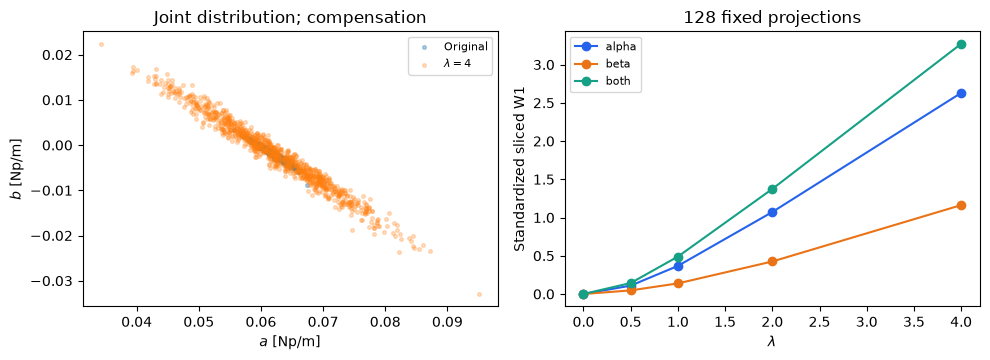

In [11]:
fig = plotting.joint_plot('synthetic', arrays); display(fig); plt.close(fig)

Наклон облака $a,b$ показывает компенсацию похожих частотных зависимостей.
Справа используется совместная информация через проекции. Одних маргинальных
расстояний недостаточно для вывода об устойчивости всего вектора параметров.

## 5.2. Экспериментальные измерения

Маркеры выделяют контрольные частотные полосы. Кривая модели подбиралась только по остальным полосам.

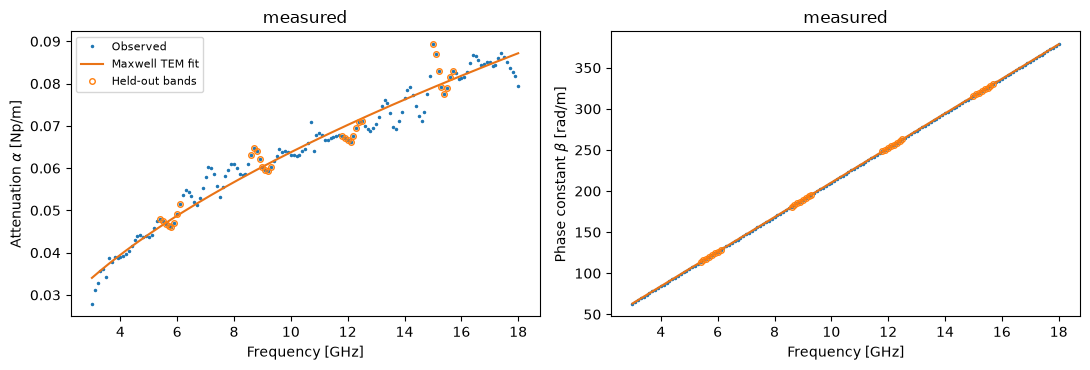

In [12]:
fig = plotting.observations('measured', report, arrays); display(fig); plt.close(fig)

Низкая ошибка фазового канала сама по себе не гарантирует точность потерь: масштаб
$\beta$ на несколько порядков больше масштаба $\alpha$. Поэтому оптимизация использует
два отдельно нормированных канала и ниже выводятся обе RMSE.

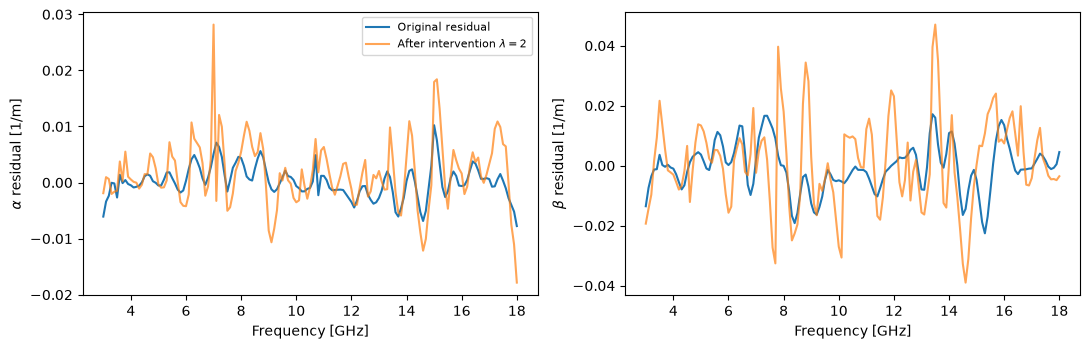

In [13]:
fig = plotting.intervention('measured', report, arrays); display(fig); plt.close(fig)

Здесь показан один пример добавления условного блочного шума с $\lambda=2$.
Для распределений ниже используется не одна эта реализация, а новая реализация
вмешательства на каждой реплике. Поэтому рассматриваются и смещение, и рост разброса оценок.

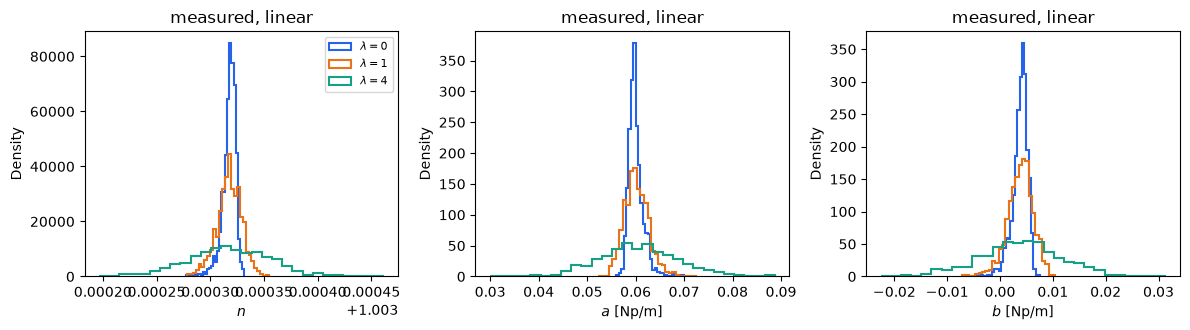

In [14]:
fig = plotting.distributions('measured', 'linear', arrays); display(fig); plt.close(fig)

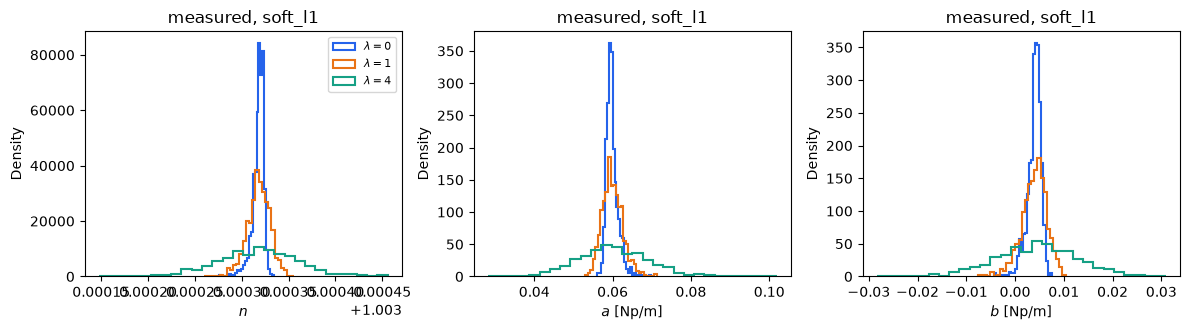

In [15]:
fig = plotting.distributions('measured', 'soft_l1', arrays); display(fig); plt.close(fig)

Гистограммы относятся к одной и той же процедуре бутстрепа; сравниваются функции ошибки
`linear` и `soft_l1`. Увеличение ширины распределения не доказывает изменение истинной
проницаемости: в этом опыте изменена наблюдаемая выборка, а не физическая среда.

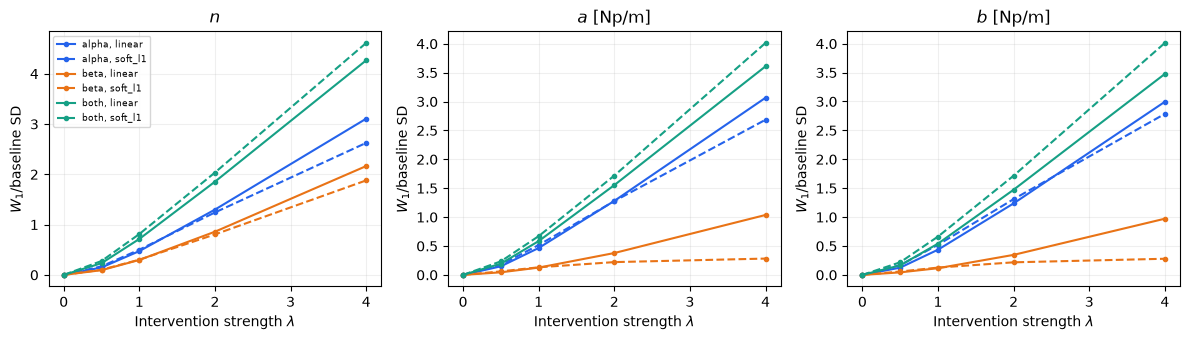

In [16]:
fig = plotting.distance_plot('measured', arrays); display(fig); plt.close(fig)

Цвет задаёт зашумлённую переменную, стиль линии — функцию ошибки. Нормировочное SD
не пересчитывается после вмешательства. В нуле все расстояния должны точно равняться нулю;
рост расстояния при увеличении шума отражает чувствительность оценки параметра.
Строгая монотонность одной конечной реализации не предполагается.

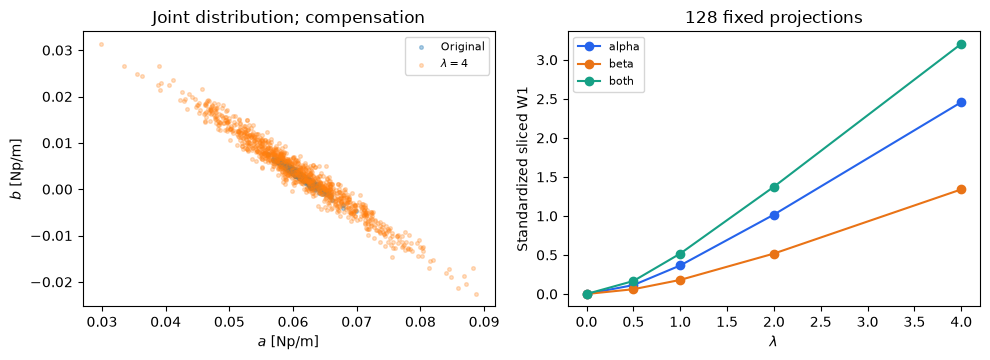

In [17]:
fig = plotting.joint_plot('measured', arrays); display(fig); plt.close(fig)

Наклон облака $a,b$ показывает компенсацию похожих частотных зависимостей.
Справа используется совместная информация через проекции. Одних маргинальных
расстояний недостаточно для вывода об устойчивости всего вектора параметров.

## 6. Критерий удаления и результаты

Правило выбора применяется к основной квадратичной функции ошибки; soft-L1 служит отдельной проверкой чувствительности распределений к функции ошибки.

**Большое расстояние не является критерием удаления.** Чувствительный параметр может
быть физически необходим. Наоборот, маленькое расстояние может означать слабую идентифицируемость.
Поэтому удаляем ветвь только при одновременном выполнении условий:

1. 95%-й процентильный интервал исходного бутстрепа содержит нулевое значение вклада
   ($n=1$ или $a=0,b=0$).
2. После фиксации этого значения остальные параметры **заново подбираются**.
   Верхняя 95%-я граница прироста контрольного нормированного RMS не превышает **0.25**.
3. При $\lambda=1$ и шуме обоих каналов $W_1/SD_0\le1$.
4. Решение об удалении подтверждается при длинах блоков **4, 8 и 12**.

Условия 0.25 и 1 — заранее заданные учебные допуски, не общепринятые физические константы
и не уровень значимости теста. Для доверительной границы прироста ошибки используются
парные бутстреп-перевыборки обучения и контроля. Контрольные полосы имеют длину 8,
поэтому для их перевыборки при проверке основного блока 12 берётся максимум 8.
Нормировочные функции $s_j(f)$ фиксированы; их собственная неопределённость не включена.

,dataset,parameter,CI95,RMS_full,RMS_removed,upper_delta95,W1_SD,block_sensitive,decision
0,synthetic,n,"[1.9999822755224135, 2.000007469485999]",1.02977,12440.839770,16913.013120,0.625078,False,keep
1,synthetic,a,"[0.0587289172794234, 0.06480070470039391]",1.02977,3.738950,4.124596,0.532665,False,keep
2,synthetic,b,"[-0.004448222138085059, 0.000708929125575195]",1.02977,1.036280,0.047203,0.575685,False,remove
3,measured,n,"[1.0033022993626695, 1.0033262471263347]",1.20652,31.054942,45.228012,0.715326,False,keep
4,measured,a,"[0.05782026125132042, 0.06348281608522745]",1.20652,3.144878,3.158536,0.585301,False,keep
5,measured,b,"[0.0004267173873991076, 0.0059817788833379645]",1.20652,1.206082,0.053321,0.541172,True,keep


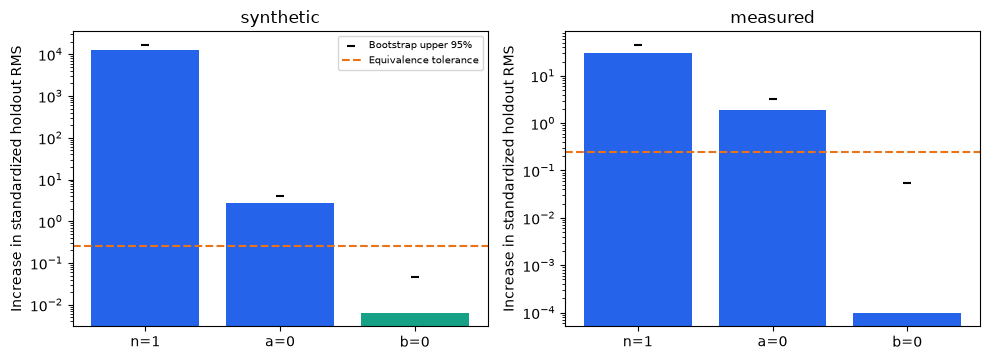

In [18]:
rows=[]
for name,info in report['datasets'].items():
    for row,final in zip(info['ablation'], info['final_decisions']):
        rows.append(dict(dataset=name,parameter=row['parameter'],CI95=row['ci95'],
            RMS_full=row['holdout_full'],RMS_removed=row['holdout_reduced'],
            upper_delta95=row['delta_upper95'],W1_SD=row['stability_W1_SD'],
            block_sensitive=final['block_length_sensitive'],decision=final['decision']))
display(pd.DataFrame(rows))
fig=plotting.ablation_plot(report);display(fig);plt.close(fig)

In [19]:
for name,info in report['datasets'].items():
    display(Markdown('**'+name+'**'))
    for final in info['final_decisions']:
        print(final)
    print('Проверки длины блока:')
    display(pd.DataFrame(info['block_sensitivity']).T)
    print('W1 в исходных единицах при lambda=1, вмешательство в оба канала:')
    display(pd.DataFrame([arrays[f'{name}_{loss}_W1'][2,2] for loss in ('linear','soft_l1')],
                         index=['linear','soft_l1'],columns=['n','a [Np/m]','b [Np/m]']))
    print('Монте-Карло уровень расхождения одинакового эмпирического распределения:')
    for loss,stats in info['loss_results'].items():
        print(loss, 'SW1(lambda=1)=',stats['SW1_both_lambda1'],
              'MC floor 95%=',stats['SW1_empirical_MC_floor95'])

**synthetic**

{'parameter': 'n', 'decision': 'keep', 'block_length_sensitive': False}
{'parameter': 'a', 'decision': 'keep', 'block_length_sensitive': False}
{'parameter': 'b', 'decision': 'remove', 'block_length_sensitive': False}
Проверки длины блока:


,ci95,decisions
4,"[[1.999983152706694, 0.059238321178529216, -0....","[keep, keep, remove]"
12,"[[1.9999824573204772, 0.05831352302752599, -0....","[keep, keep, remove]"


W1 в исходных единицах при lambda=1, вмешательство в оба канала:


,n,a [Np/m],b [Np/m]
linear,0.000004,0.000823,0.000755
soft_l1,0.000004,0.000858,0.000775


...

{'parameter': 'n', 'decision': 'keep', 'block_length_sensitive': False}
{'parameter': 'a', 'decision': 'keep', 'block_length_sensitive': False}
{'parameter': 'b', 'decision': 'keep', 'block_length_sensitive': True}
Проверки длины блока:


,ci95,decisions
4,"[[1.0033031881205183, 0.05799103510969582, 0.0...","[keep, keep, keep]"
12,"[[1.0032961052967033, 0.057718390936902675, -0...","[keep, keep, remove]"


W1 в исходных единицах при lambda=1, вмешательство в оба канала:


,n,a [Np/m],b [Np/m]
linear,0.000004,0.000891,0.000791
soft_l1,0.000005,0.001013,0.000939


Монте-Карло уровень расхождения одинакового эмпирического распределения:
linear SW1(lambda=1)= 0.5175761956492542 MC floor 95%= 0.08150688945531773
soft_l1 SW1(lambda=1)= 0.6005785634327001 MC floor 95%= 0.07873354144613004


### Вывод

На синтетике коэффициент $b$ в генераторе равен нулю. Процедура разрешает удалить
именно эту ветвь; сохраняет показатель преломления и проводниковый вклад.
Это проверка способности метода распознавать заведомо отсутствующий член.

На измерениях $n$ и $a$ сохраняются. Для $b$ основной 95%-й интервал не содержит нуля,
хотя ухудшение контрольной ошибки после удаления мало. При увеличении блока до 12
вывод об этом коэффициенте меняется. Поэтому **окончательное решение — сохранить $b$**:
обоснования устойчивого удаления нет. Это не доказательство ненулевых потерь конкретного
материала; модельная ошибка и обработка VNA тоже могут давать такой член.

Бутстреп оценивает изменчивость оценок по выбранным частотным полосам, но не полную
неопределённость измерительной цепи, коррелированные систематические ошибки или
неопределённость собственного алгоритма извлечения $\gamma$. Уровень Монте-Карло показывает
только конечность выборки параметров; это не порог статистического теста на реальных данных.
Выводы относятся к данной линии, полосе 3–18 ГГц, модели и выбранным допускам.

## 7. Источники и воспроизводимость

1. **Основа и старый код:** [gkarpeev/maxwell](https://github.com/gkarpeev/maxwell/tree/b88901cc688be82a7de1716ef428026a33e4c7db), commit `b88901cc688be82a7de1716ef428026a33e4c7db`.
   Избранные исходники сохранены без изменения; SHA-256 в `sources.json`. Общая лицензия
   в этой версии не обнаружена; новая лицензия за автора не назначается.
2. **Уравнения:** Oskooi et al. *Meep*, CPC 181 (2010), 687–702,
   [DOI](https://doi.org/10.1016/j.cpc.2009.11.008);
   [официальная документация Maxwell/FDTD](https://meep.readthedocs.io/en/latest/Introduction/).
3. **Реальные измерения:** Hatab et al. *Propagation Constant Measurement Based on a Single
   Transmission Line Standard Using a Two-port VNA*, Sensors 23 (2023), 4548,
   [DOI](https://doi.org/10.3390/s23094548), [авторский текст](https://arxiv.org/abs/2302.13859),
   [DOI данных](https://doi.org/10.3217/6bd26-5cp67),
   [код и измерения](https://github.com/ZiadHatab/two-port-single-line-propagation-constant/tree/8785259053c0b9ccb5ae9d4d29c20f36e243f066), BSD-3-Clause.
4. **Частотные потери линии:** Bobowski (2020), *Modeling and measuring the non-ideal
   characteristics of transmission lines*, [arXiv:2006.14381](https://arxiv.org/abs/2006.14381).
   Использованы физические мотивы распределённой RLCG-модели, не его данные.
5. **Бутстреп:** Efron (1979), [DOI 10.1214/aos/1176344552](https://doi.org/10.1214/aos/1176344552).
6. **Зависимые блоки:** Künsch (1989), *The Jackknife and the Bootstrap for General Stationary Observations*,
   [DOI 10.1214/aos/1176347265](https://doi.org/10.1214/aos/1176347265).
   Применение к частотным остаткам здесь — наше допущение, проверенное лишь по длине блока.
7. **Метрика:** [SciPy Wasserstein-1](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wasserstein_distance.html);
   Ramdas, García, Cuturi (2015), [arXiv:1509.02237](https://arxiv.org/abs/1509.02237).
8. **Оптимизация:** [SciPy least_squares](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.least_squares.html).

Код отделён от ноутбука: `model.py`, `statistics.py`, `experiment.py`, `data.py`, `plotting.py`.
Полный запуск: `python -m lab02.run --bootstrap 1000 --rebuild-data`.
Исходные измерения включены, сеть не нужна. Численные результаты, все выборки параметров,
матрицы смежности и выбранные графы сохранены в `results/`. Рисунки — в `figures/`.